# Image Colorization — Pretrained ResNet18 Encoder

До этого мы обучали кастомную U-Net (40 эпох). Результаты показали, что модель предсказывает слишком маленькие значения каналов `ab`, из-за чего изображения получаются достаточно тусклыми

Одна из возможных причин заключается в том, что похожие объекты могут иметь разные цвета. При использовании L1 Loss модели может быть выгоднее предсказывать значения ближе к нейтральным, чтобы уменьшить ошибку

Попробуем заменить encoder нашей U-Net на предобученную **ResNet18 (ImageNet)**. Такая модель уже умеет извлекать полезные признаки из изображений, что может помочь улучшить качество колоризации

Сначала попробуем использовать ResNet18 с замороженными весами (**feature extraction**), а затем дообучить часть encoder (**fine-tuning**) и сравнить результаты

ResNet18 была предобучена на RGB-изображениях, поэтому ожидает на вход 3 канала. У нас же изображение представлено только одним каналом L из цветового пространства LAB

Продублируем канал L три раза, получив изображение с 3 одинаковыми каналами, чтобы не менять архитектуру ResNet18 и сохранить предобученные веса

Таким образом, входной тензор изменится с [B, 1, 128, 128] на [B, 3, 128, 128]. При этом изображение не станет цветным, поскольку все три канала содержат одинаковую информацию о яркости

## 1. Setup and Imports

In [ ]:
import torch
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from torchvision import transforms
from torch import nn
from image_colorization.unet import UNet
from image_colorization.resnet_unet import ResNetUNet
from image_colorization.dataset import ColorizationDataset
from image_colorization.color_utils import denormalize_lab
from image_colorization.training import training_epoch, validation_epoch, train_model
from image_colorization.dataset import Dataset
from image_colorization.dataloaders import create_dataloaders
from pathlib import Path
from skimage.color import lab2rgb

## 2. Experiment Configuration

In [ ]:
NUM_EPOCHS = 20
BATCH_SIZE = 32
LEARNING_RATE = 1e-3

config = {
    "architecture": "resnet18_unet",
    "encoder": "ResNet18",
    "pretrained": True,
    "encoder_frozen": True,
    "num_epochs": NUM_EPOCHS,
    "batch_size": BATCH_SIZE,
    "learning_rate": LEARNING_RATE,
    "optimizer": "AdamW",
    "loss": "L1"
}

## 3. Weights & Biases

In [ ]:
import wandb

wandb.login()

run = wandb.init(
    entity="arzushkaB",
    project="image-colorization",
    name="resnet18_unet_frozen_encoder",
    config=config
)

## 4. Data Paths and Checkpoints

In [ ]:
images_dir = Path("../VOCdevkit/VOC2012/JPEGImages")
train_path = Path("../data/splits/train.txt")
val_path = Path("../data/splits/val.txt")

checkpoint_dir = Path("/content/drive/MyDrive/image-colorization/checkpoints")
checkpoint_dir.mkdir(parents=True, exist_ok=True)

experiment_name = "resnet18_unet_frozen_encoder"
last_path = checkpoint_dir / f"{experiment_name}_last.pt"
best_path = checkpoint_dir / f"{experiment_name}_best.pt"

## 5. DataLoaders

In [ ]:
train_loader, val_loader = create_dataloaders(images_dir=images_dir,
                                              train_path=train_path,
                                              val_path=val_path)

## 6. Model Training

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = ResNetUNet().to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE)
criterion = nn.L1Loss()
train_losses, val_losses = train_model(model=model,
                                       criterion=criterion,
                                       optimizer=optimizer,
                                       train_loader=train_loader,
                                       val_loader=val_loader,
                                       num_epochs=NUM_EPOCHS,
                                       device=device,
                                       last_path=last_path,
                                       best_path=best_path,
                                       run=run)

print(f"Train L1: {train_losses[-1]:.5f}")
print(f"Val L1: {val_losses[-1]:.5f}")

run.finish()

## 7. Best Checkpoint and Inference

In [ ]:
L, ab = next(iter(val_loader))

In [ ]:
checkpoint_path = Path("../checkpoints/resnet18_unet_frozen_encoder_best.pt")
checkpoint = torch.load(checkpoint_path,
                       map_location='cpu',
                       weights_only=True)

In [ ]:
print(checkpoint.keys())
print(checkpoint["epoch"])

dict_keys(['epoch', 'model_state_dict', 'optimizer_state_dict', 'train_losses', 'val_losses'])
9


In [ ]:
model = ResNetUNet().to('cpu')
model.load_state_dict(state_dict=checkpoint['model_state_dict'])
model.eval()

ResNetUNet(
  (normalize): Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1)

In [ ]:
with torch.no_grad():
    pred_ab = model(L)
print(pred_ab.shape)

torch.Size([32, 2, 128, 128])


## 8. Image Reconstruction and Visualization

In [ ]:
samples = []
for i in range(len(L)):
    samples.append({
        "L": L[i].squeeze(0).cpu().numpy(),
        "true_ab": ab[i].permute(1, 2, 0).cpu().numpy(), 
        "pred_ab": pred_ab[i].permute(1, 2, 0).cpu().numpy()
    })

denorm_lab_images = []
for sample in samples:
    denorm_lab_images.append(
        {"true_lab": denormalize_lab(sample["L"], sample["true_ab"]),
         "pred_lab": denormalize_lab(sample["L"], sample["pred_ab"])
    })


rgb_images = []
for img in (denorm_lab_images):
    rgb_images.append(
        {"true_rgb": lab2rgb(img['true_lab']),
         "pred_rgb": lab2rgb(img['pred_lab'])
    })

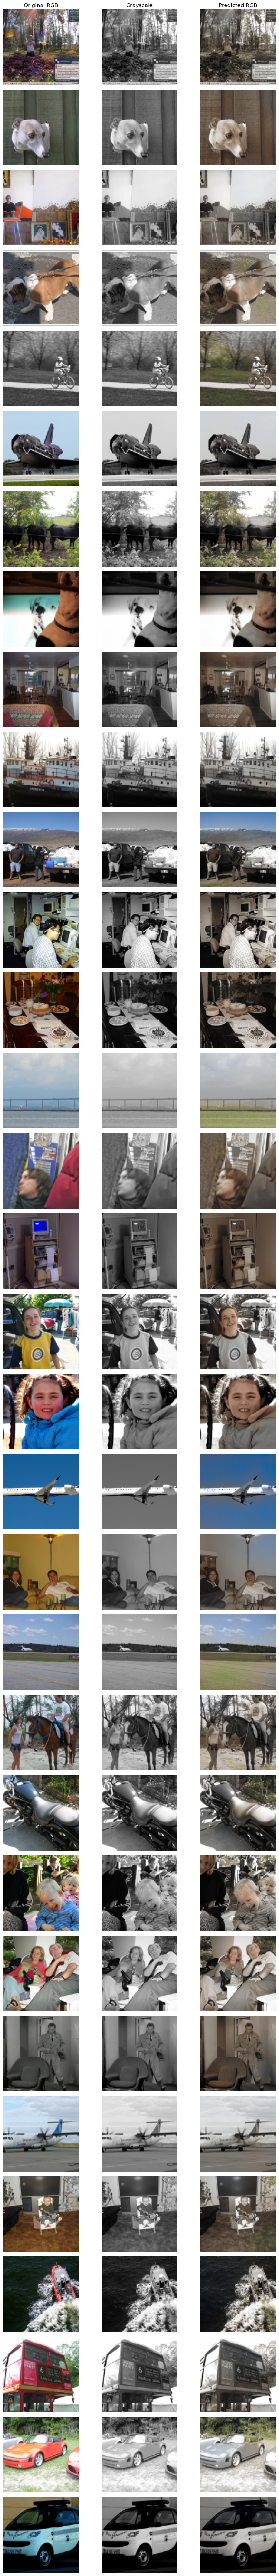

In [ ]:
n_show = 32

fig, axes = plt.subplots(n_show, 3, figsize=(10, n_show * 2.5))

for i in range(n_show):
    axes[i, 0].imshow(rgb_images[i]["true_rgb"])
    axes[i, 1].imshow(samples[i]["L"], cmap="gray", vmin=0, vmax=1)
    axes[i, 2].imshow(rgb_images[i]["pred_rgb"])

    for ax in axes[i]:
        ax.axis("off")

axes[0, 0].set_title("Original RGB")
axes[0, 1].set_title("Grayscale")
axes[0, 2].set_title("Predicted RGB")

plt.tight_layout()
plt.show()

## 9. Visual Analysis

По полученным изображениям видно, что модель при энкодере в виде предобученного ResNet18 лучше научилась определять локализацию цветовых облостей. Видно что на большинстве изображенийс людьми контур окрашивания лиц стал четче и границы более точные. Логично предположить что на естественных фотографиях человеческая кожа имеет довольно ограниченный диапазон распространённых оттенков по сравнению с произвольными цветами одежды

## 10. Color Channel Statistics

In [ ]:
for group, x in [("True", ab), ("Pred", pred_ab)]:
    print(group)
    print("Mean a:", x[:, 0].mean().item())
    print("Mean b:", x[:, 1].mean().item())
    print("Mean |a|:", x[:, 0].abs().mean().item())
    print("Mean |b|:", x[:, 1].abs().mean().item())
    print()

True
Mean a: 0.014557400718331337
Mean b: 0.015374312177300453
Mean |a|: 0.04467958211898804
Mean |b|: 0.08364629745483398

Pred
Mean a: 0.006746578495949507
Mean b: 0.027952590957283974
Mean |a|: 0.012824725359678268
Mean |b|: 0.048977404832839966



## 11. L1 Evaluation

In [ ]:
gray_ab = torch.zeros_like(ab)
print("Gray baseline L1:", criterion(gray_ab, ab).item())
print("UNetResnet L1:", criterion(pred_ab, ab).item())

Gray baseline L1: 0.06416293978691101
UNetResnet L1: 0.06049323081970215


## 12. Results and Conclusions

Использование предобученного ResNet18 в качестве encoder позволило улучшить результаты по сравнению с обычной U-Net.

На одном и том же validation-батче получили следующие значения L1:

- **Grayscale baseline:** 0.06416
- **U-Net (40 эпох):** 0.06227
- **ResNet18-U-Net:** 0.06049

Таким образом, ошибка относительно U-Net после 40 эпох снизилась примерно на **2.9%**.

Также сравнили средние абсолютные значения цветовых каналов `a` и `b`. По сравнению с обычной U-Net значения `Mean |a|` увеличились с 0.01102 до 0.01282, а `Mean |b|` — с 0.04666 до 0.04898.

Это говорит о том, что новая модель стала предсказывать немного более выраженные цветовые компоненты. Однако их значения всё ещё значительно ниже исходных, особенно для канала `a`.

По визуализации также заметно, что модель стала точнее окрашивать отдельные области, особенно лица людей. При этом проблема недостаточной насыщенности цветов сохранилась. Например, одежда часто приобретает нейтральные бежевые или коричневые оттенки вместо исходных ярких цветов.

**Вывод:** предобученный encoder помог улучшить качество предсказаний и точность локализации цветовых областей, однако полностью проблему тусклой колоризации не решил. Вероятно, это связано не только с архитектурой, но и с использованием `L1Loss`, которая не учитывает неоднозначность возможных цветов.